In [40]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 18})

In [41]:
def krog(R,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    n=0
    r=(np.random.uniform(0,R))**(1/3) #lega
    #phi = 2*np.pi*np.random.random() #ni treba?!
    #smer = 2*np.pi*np.random.random() #ni OK?
    smer = np.arccos(2*np.random.random()-1) #theta
    dolžina = np.random.exponential(scale=pp) # pot delčka
    d=-r*np.cos(smer)+R*np.sqrt(1-(r/R)**2*(1-(np.cos(smer))**2))
    if dolžina > d:
        n=1
    return n
def MC_krog1(R,pp,N_max):#malenkost počasneje!!
    '''R=radij kroga, pp=prosta pot delcev, N_max št. iteracij'''
    N=0
    n=0
    while N<N_max:
        r=np.sqrt(np.random.uniform(0,R)) #lega
        #phi = 2*np.pi*np.random.random() #ni treba?!
        #smer = 2*np.pi*np.random.random() #ni OK?
        smer = np.arccos(2*np.random.random()-1) #theta
        dolžina = np.random.exponential(scale=pp) # pot delčka
        d=-r*np.cos(smer)+R*np.sqrt(1-(r/R)**2*(1-(np.cos(smer))**2))
        if dolžina > d:
            n+=1
            N+=1
        else:
            N+=1
    return n/N
def MC_krog(R,pp,N_max):
    '''R=radij kroga, pp=prosta pot delcev, N_max št. iteracij'''
    N=0
    n=0
    while N<N_max:
        n+=krog(R,pp)
        N+=1
    return n/N

## delež pobeglih

In [42]:
R=1
pp=R
N_max0=np.logspace(3,7,30)
pobeg=[]
for N_max in N_max0:
    pi=MC_krog(R,pp,N_max)
    pobeg.append(pi)

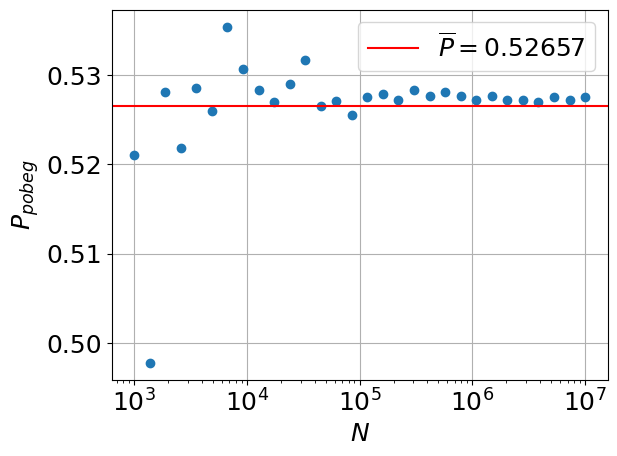

In [43]:
plt.plot(N_max0,np.array(pobeg),'o')
plt.xlabel('$N$')
plt.axhline(np.average(pobeg),color='r',label=f'$\overline{{P}}=${round(np.average(pobeg),5)}')
plt.legend()
plt.ylabel('$P_{pobeg}$')
plt.xscale('log')
plt.grid()
#plt.savefig('slike/gama_N.pdf',bbox_inches='tight')

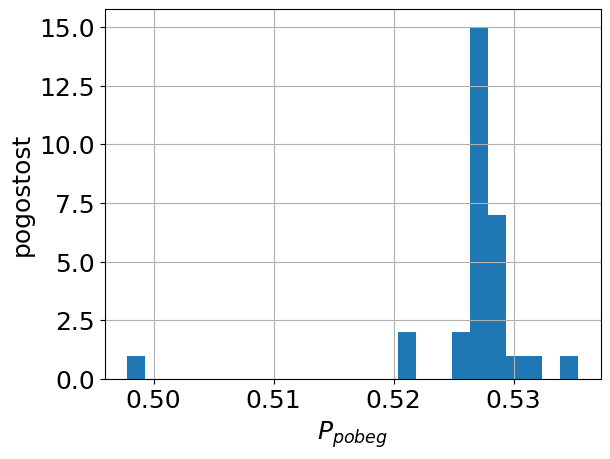

In [44]:
plt.hist(pobeg,bins=25)
plt.xlabel('$P_{pobeg}$')
plt.ylabel('pogostost')
plt.grid()
#plt.savefig('slike/gama_porazd.pdf',bbox_inches='tight')

## vpliv proste poti

In [45]:
R=1
N_max=100000
pp0=np.logspace(-3,0,20)
pp0=np.append(pp0,np.logspace(0,3,20))
pobeg=[]
for pp in pp0:
    pi=MC_krog(R,pp,N_max)
    pobeg.append(pi)

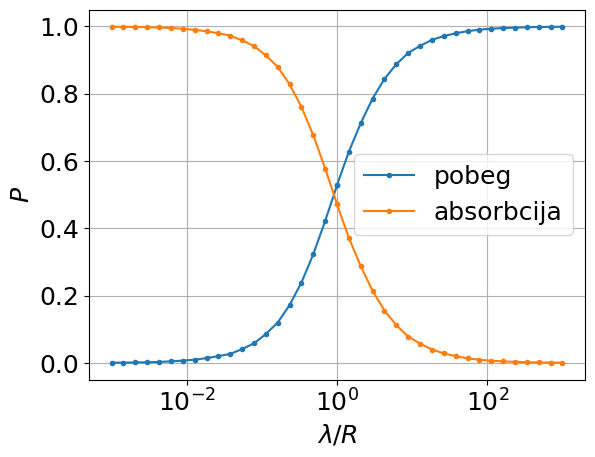

In [46]:
plt.plot(pp0/R,np.array(pobeg),'.-', label='pobeg')
plt.plot(pp0/R,1-np.array(pobeg),'.-', label='absorbcija')
plt.xlabel('$\lambda/R$')
plt.legend()
plt.ylabel('$P$')
plt.xscale('log')
plt.grid()
#plt.savefig('slike/gama_pp.pdf',bbox_inches='tight')

## napaka

In [47]:
R=1
N_max0=np.logspace(2,6,5)
pp0=np.logspace(-3,0,7)
pp0=np.append(pp0,np.logspace(0,3,7))
pobeg=[]
for N_max in N_max0:
    ppi=[]
    for pp in pp0:
        pi=MC_krog(R,pp,N_max)
        ppi.append(pi)
    pobeg.append(ppi)

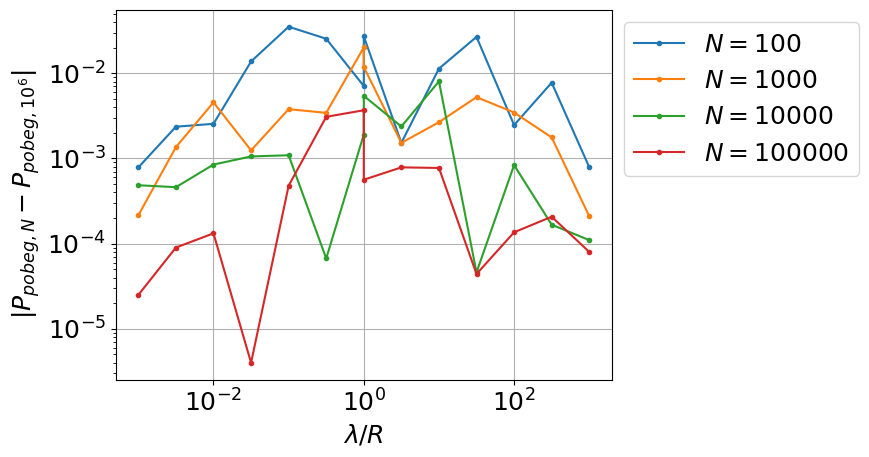

In [48]:
pobeg=np.array(pobeg)
for i in range(len(pobeg)-1):
    plt.plot(pp0, np.abs(pobeg[-1]-pobeg[i]), '.-',label=f'$N=${int(N_max0[i])}')
plt.xscale('log')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1,1))
plt.grid()
plt.xlabel('$\lambda/R$')
plt.ylabel('$|P_{pobeg,N}-P_{pobeg,10^6}|$')
#plt.savefig('slike/gama_napaka.pdf',bbox_inches='tight')

# 1D model

In [49]:
def model_1D(R,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    n=0
    r=(np.random.uniform(0,R))**(1/3) #lega
    dolžina = np.random.exponential(scale=pp) # pot delčka
    d=R-r
    if dolžina > d:
        n=1
    return n
def MC_1D(R,pp,N_max):
    N=0
    n=0
    while N < N_max:
        n += model_1D(R,pp)
        N+=1
    return n/N

In [50]:
# R=1
# pp=R
# N_max0=np.logspace(3,7,30)
# pobeg=[]
# for N_max in N_max0:
#     pi=MC_1D(R,pp,N_max)
#     pobeg.append(pi)

In [51]:
# pobeg=np.array(pobeg)
# cmap = plt.get_cmap('viridis')
# fig, ax = plt.subplots(1,1)
# for i in range(len(pobeg)):
#     ci= cmap(pobeg[i] / max(pobeg))
# ax.plot(N_max0, (pobeg-pobeg[-1])/pobeg[-1],'o',color=ci)
# #plt.plot(N_max0,np.array(pobeg),'o')
# plt.xlabel('$N$')
# #plt.axhline(np.average(pobeg),color='r',label=f'$\overline{{P}}=${round(np.average(pobeg),5)}')
# #plt.legend()
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(pobeg), vmax=max(pobeg)))
# sm.set_array([])
# cbar = fig.colorbar(sm, ax=ax, orientation='vertical', label='ime')
# plt.ylabel('$P_{pobeg}$')
# plt.xscale('log')
# plt.grid()
# #plt.savefig('slike/gama_N_1D.pdf',bbox_inches='tight')

In [52]:
#1D
R=1
N_max=100000
pp0=np.logspace(-3,0,20)
pp0=np.append(pp0,np.logspace(0,3,20))
pobeg_1D=[]
for pp in pp0:
    pi=MC_1D(R,pp,N_max)
    pobeg_1D.append(pi)

In [53]:
# klasičen
pobeg=[]
for pp in pp0:
    pi=MC_krog(R,pp,N_max)
    pobeg.append(pi)

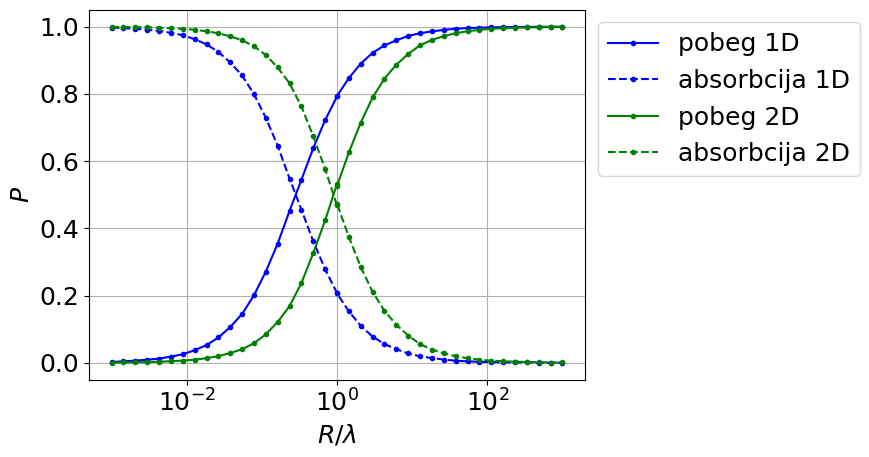

In [54]:
plt.plot(pp0/R,np.array(pobeg_1D),'b.-', label='pobeg 1D')
plt.plot(pp0/R,1-np.array(pobeg_1D),'b.--', label='absorbcija 1D')
plt.plot(pp0/R,np.array(pobeg),'g.-', label='pobeg 2D')
plt.plot(pp0/R,1-np.array(pobeg),'g.--', label='absorbcija 2D')
plt.xlabel('$R/\lambda$')
plt.legend(bbox_to_anchor=(1,1),ncol=1)
plt.ylabel('$P$')
plt.xscale('log')
plt.grid()
#plt.savefig('slike/gama_pp_1D.pdf',bbox_inches='tight')

## krogla

In [55]:
def krogla(R,pp):
    '''R=radij kroga, pp=prosta pot delcev'''
    n=0
    r=np.sqrt(np.random.uniform(0,R)) #lega
    phi = 2*np.pi*np.random.random()
    theta = np.arccos(2*np.random.random()-1) #theta lega
    smer_phi= 2*np.pi*np.random.random()
    smer_theta = np.arccos(2*np.random.random()-1)
    dolžina = np.random.exponential(scale=pp) # pot delčka
    alpha = np.sin(theta)*np.cos(phi)*np.sin(smer_theta)*np.cos(smer_phi) + np.sin(theta)*np.sin(phi)*np.sin(smer_theta)*np.sin(smer_phi) + np.cos(theta)*np.cos(smer_theta)
    d=R-r*alpha #nova formula!!
    if dolžina > d:
        n=1
    return n
def MC_krogla(R,pp,N_max):
    '''R=radij kroga, pp=prosta pot delcev, N_max št. iteracij'''
    N=0
    n=0
    while N<N_max:
        n+=krogla(R,pp)
        N+=1
    return n/N

In [56]:
# klasičen
R=1
N_max=100000
pp0=np.logspace(-3,0,10)
pp0=np.append(pp0,np.logspace(0,3,10))
pobeg_2D=[]
for pp in pp0:
    pi=MC_krog(R,pp,N_max)
    pobeg_2D.append(pi)

In [57]:
#1D
pobeg_1D=[]
for pp in pp0:
    pi=MC_1D(R,pp,N_max)
    pobeg_1D.append(pi)

In [58]:
# 3D
pobeg=[]
for pp in pp0:
    pi=MC_krogla(R,pp,N_max)
    pobeg.append(pi)

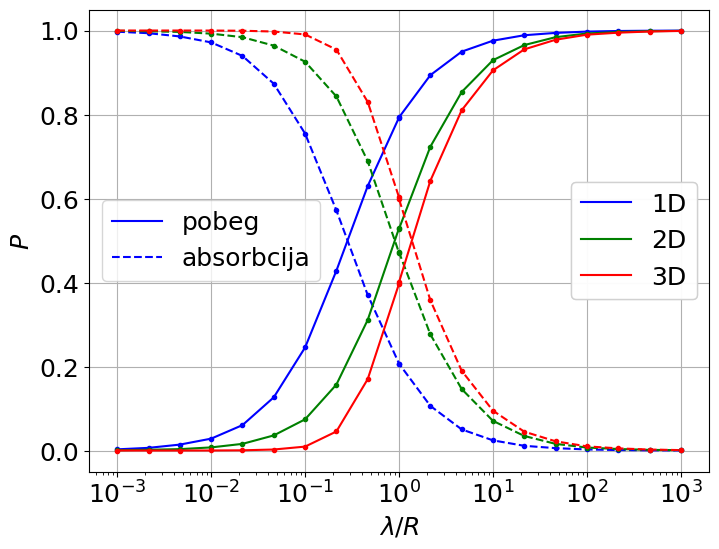

In [59]:
plt.figure(figsize=(8,6))
plt.plot(pp0/R,np.array(pobeg_1D),'b.-', label='pobeg 1D')
plt.plot(pp0/R,1-np.array(pobeg_1D),'b.--', label='absorbcija 1D')
plt.plot(pp0/R,np.array(pobeg_2D),'g.-', label='pobeg 2D')
plt.plot(pp0/R,1-np.array(pobeg_2D),'g.--', label='absorbcija 2D')
plt.plot(pp0/R,np.array(pobeg),'r.-', label='pobeg 3D')
plt.plot(pp0/R,1-np.array(pobeg),'r.--', label='absorbcija 3D')

legend_line_styles = plt.legend(handles=[plt.Line2D([], [], color='b', linestyle='-', label='pobeg'),
                                         plt.Line2D([], [], color='b', linestyle='--', label='absorbcija')],
                                loc='center left', ncol=1)
plt.gca().add_artist(legend_line_styles)  # Add this to keep the first legend while adding the second one
legend_colors = plt.legend(handles=[plt.Line2D([], [], color='blue', label='1D'),
                                     plt.Line2D([], [], color='green', label='2D'),
                                     plt.Line2D([], [], color='red', label='3D')],
                           loc='right', ncol=1)
plt.gca().add_artist(legend_colors)  # Add the second legend after the first one
plt.xlabel('$\lambda/R$')
plt.ylabel('$P$')
plt.xscale('log')
#plt.legend(bbox_to_anchor=(1,1),ncol=1)
plt.grid()
#plt.savefig('slike/gama_pp_1D_2D_3D.pdf',bbox_inches='tight')

In [84]:
R=1
pp=R
N_max0=np.logspace(3,7,20)
pobeg1=[]
pobeg2=[]
pobeg3=[]
for N_max in N_max0:
    pi=MC_1D(R,pp,N_max)
    pobeg1.append(pi)
    pi=MC_krog(R,pp,N_max)
    pobeg2.append(pi)
    pi=MC_krogla(R,pp,N_max)
    pobeg3.append(pi)

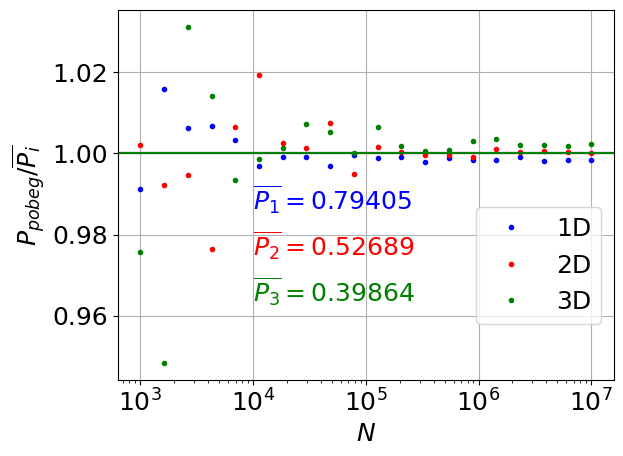

In [112]:
plt.plot(N_max0,np.array(pobeg1)/np.average(pobeg1),'b.',label='1D')
plt.plot(N_max0,np.array(pobeg2)/np.average(pobeg2),'r.',label='2D')
plt.plot(N_max0,np.array(pobeg3)/np.average(pobeg3),'g.',label='3D')

plt.axhline(np.average(pobeg1)/np.average(pobeg1),color='b')
plt.axhline(np.average(pobeg2)/np.average(pobeg2),color='r')
plt.axhline(np.average(pobeg3)/np.average(pobeg3),color='g')
plt.text(10000, np.average(pobeg1)/max(pobeg1), f'$\overline{{P_1}}=${round(np.average(pobeg1), 5)}', ha='left', va='bottom', color='b')
plt.text(10000, np.average(pobeg2)/max(pobeg2)-0.008, f'$\overline{{P_2}}=${round(np.average(pobeg2), 5)}', ha='left', va='bottom', color='r')
plt.text(10000, np.average(pobeg3)/max(pobeg3)-0.008, f'$\overline{{P_3}}=${round(np.average(pobeg3), 5)}', ha='left', va='bottom', color='g')

plt.legend(loc='best', bbox_to_anchor=(1,0.5))
plt.xlabel('$N$')
plt.ylabel('$P_{pobeg}/\overline{P_i}$')
plt.xscale('log')
plt.grid()
#plt.savefig('slike/gama_N_vse_dim.pdf',bbox_inches='tight')